## Step 0: Setup and Imports

In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split # For splitting sequences, not raw data
from sklearn.metrics import mean_squared_error, mean_absolute_error
from torch.utils.data import DataLoader, TensorDataset
import os # For checking file existence

# Set a random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set device for PyTorch (GPU if available, else CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Use a refined threshold for custom accuracy
ACCURACY_THRESHOLD_KW = 50.0 # Or 100.0, set the threshold to 1% to 5% of rated power (2000 kW)

# Assuming you have defined your rated_power somewhere, e.g.:
RATED_POWER_KW = 2000.0 # From your input

## Step 1: Data Loading and Initial Preprocessing

In [3]:
# Cell 2: Dummy Data Generation (REPLACE WITH YOUR REAL DATA LOADING)

# Create a dummy CSV file for demonstration purposes
# In your actual use, you will point to your existing CSV.
csv_path = '../../data/raw/第1台风机的数据.csv'

# Your data loading and preprocessing function
def load_and_preprocess_data(file_path):
    """
    Loads data from CSV, sets timestamp as index, and handles initial preprocessing.
    Assumes timestamp is in a recognizable format (e.g., ISO 8601).
    """
    print(f"\nLoading data from {file_path}...")
    try:
        df = pd.read_csv(file_path, index_col=0, parse_dates=True)
        
        df = df.rename(columns={
            "风速": "wind_speed",
            "风向": "wind_direction",
            "平均功率": "power",
            "平均风速(m/s)": "avg_wind_speed",
            "平均风角度（对北）": "avg_wind_direction",
            "平均室外温度": "temperature"
            # If your CSV has a turbine ID column, add it here, e.g., "风机": "turbine_id"
        })
        
        # Ensure the index is sorted chronologically
        df = df.sort_index()
        
        # Drop columns that are not directly used as features for the model
        # Assuming 'avg_wind_speed' and 'avg_wind_direction' are redundant with 'wind_speed' and 'wind_direction'
        df = df.drop(columns=["风机", "avg_wind_speed", "avg_wind_direction"], errors='ignore')
        
        # Ensure expected core columns exist after renaming
        required_cols = ['wind_speed', 'wind_direction', 'power', 'temperature']
        for col in required_cols:
            if col not in df.columns:
                raise ValueError(f"Missing required column after renaming: '{col}'. Available columns: {df.columns.tolist()}")
        
        print("Data loaded successfully.")
        return df
    except Exception as e:
        print(f"Error loading or parsing data from {file_path}: {e}")
        return None

# Load the data
df_raw = load_and_preprocess_data(csv_path)
if df_raw is None:
    print("Exiting due to data loading error.")
    exit()

print("\nFirst 5 rows of raw data:")
print(df_raw.head())
print("\nData Info:")
df_raw.info()


Loading data from ../../data/raw/第1台风机的数据.csv...
Data loaded successfully.

First 5 rows of raw data:
                     wind_speed  wind_direction    power  temperature
2019-10-16 15:25:00       8.120          75.890  1289.01        22.19
2019-10-16 15:30:00       0.000           0.000  1519.29        22.14
2019-10-16 15:35:00       9.010          74.140  1436.38        22.14
2019-10-16 15:45:00       9.430          71.730  1663.22        22.01
2019-10-16 15:55:00       9.439          73.688  1579.56        21.98

Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 184341 entries, 2019-10-16 15:25:00 to 2022-07-20 23:55:00
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   wind_speed      184341 non-null  float64
 1   wind_direction  184341 non-null  float64
 2   power           184341 non-null  float64
 3   temperature     184341 non-null  float64
dtypes: float64(4)
memory usage: 7.0 MB


## Step 2: Data Cleaning and Feature Engineering

In [4]:
# Cell 3: Data Cleaning and Feature Engineering

# 2.1 Handle Missing Values
print("\nChecking for missing values before handling:")
print(df_raw.isnull().sum())

# For time series, interpolation is generally preferred over dropping
# Use 'time' method for interpolation based on index, which is robust to irregular intervals
df_processed = df_raw.interpolate(method='time', limit_direction='both') # Fill NaNs forward and backward

print("\nMissing values after interpolation:")
print(df_processed.isnull().sum())

# 2.2 Verify and Resample Data Frequency (if needed)
# Ensure data is at a consistent 15-minute frequency
print(f"\nOriginal data frequency (inferred): {pd.infer_freq(df_processed.index)}")
target_freq = '15min'

# Check if there are missing timestamps and reindex if necessary
if pd.infer_freq(df_processed.index) != target_freq:
    print(f"Resampling data to {target_freq} frequency and interpolating...")
    df_processed = df_processed.asfreq(target_freq)
    df_processed = df_processed.interpolate(method='time', limit_direction='both')
    print(f"New data frequency (inferred): {pd.infer_freq(df_processed.index)}")
else:
    print(f"Data already at {target_freq} frequency.")

# Handle any remaining NaNs after resampling (e.g., if the very start/end are NaN after reindex)
df_processed.dropna(inplace=True)
if df_processed.empty:
    print("DataFrame is empty after dropping NaNs. Check your data.")
    exit()

print(f"\nCleaned data shape: {df_processed.shape}")
print(df_processed.head())

# 2.3 Feature Engineering
print("\nPerforming Feature Engineering...")

# Time-based features
df_processed['hour'] = df_processed.index.hour
df_processed['day_of_week'] = df_processed.index.dayofweek
df_processed['day_of_year'] = df_processed.index.dayofyear
df_processed['month'] = df_processed.index.month

# Cyclical features for hour, day_of_year, day_of_week (to help model understand periodicity)
df_processed['hour_sin'] = np.sin(2 * np.pi * df_processed['hour'] / 24)
df_processed['hour_cos'] = np.cos(2 * np.pi * df_processed['hour'] / 24)
df_processed['day_of_week_sin'] = np.sin(2 * np.pi * df_processed['day_of_week'] / 7)
df_processed['day_of_week_cos'] = np.cos(2 * np.pi * df_processed['day_of_week'] / 7)
df_processed['day_of_year_sin'] = np.sin(2 * np.pi * df_processed['day_of_year'] / 365.25)
df_processed['day_of_year_cos'] = np.cos(2 * np.pi * df_processed['day_of_year'] / 365.25)

# Convert wind direction into U and V components (better for ML models)
# Assuming wind_direction is in degrees
df_processed['wind_u'] = -df_processed['wind_speed'] * np.sin(np.deg2rad(df_processed['wind_direction']))
df_processed['wind_v'] = -df_processed['wind_speed'] * np.cos(np.deg2rad(df_processed['wind_direction']))

# --- NEW: Lagged Features ---
# Lagged power and wind speed are crucial for short-term forecasting.
# We'll use lags corresponding to the first few forecast horizons.
# For 15-min resolution:
# Lag 1: Previous 15 min
# Lag 2: Previous 30 min
# Lag 4: Previous 1 hour
# Lag 8: Previous 2 hours
# Lag 16: Previous 4 hours (could be relevant for longer look-back)

# Consider a few different lags:
lags_to_use = [1, 2, 4, 8, 16] # In 15-minute intervals

for lag in lags_to_use:
    df_processed[f'power_lag_{lag}'] = df_processed['power'].shift(lag)
    df_processed[f'wind_speed_lag_{lag}'] = df_processed['wind_speed'].shift(lag)

# --- NEW: Lagged Differences (Rate of Change) ---
# These features can help the model recognize sudden changes in the input sequence.
# Calculate difference over the most recent few steps
df_processed['power_diff_15min'] = df_processed['power'].diff(1)
df_processed['wind_speed_diff_15min'] = df_processed['wind_speed'].diff(1)

# Also consider differences over slightly longer intervals if ramps are longer
df_processed['power_diff_1hr'] = df_processed['power'].diff(4) # 4 * 15min = 1 hour
df_processed['wind_speed_diff_1hr'] = df_processed['wind_speed'].diff(4)

# Fill NaNs created by .diff() before dropping
# Using fillna(0) for differences is common, or you can interpolate/backfill
df_processed['power_diff_15min'].fillna(0, inplace=True)
df_processed['wind_speed_diff_15min'].fillna(0, inplace=True)
df_processed['power_diff_1hr'].fillna(0, inplace=True)
df_processed['wind_speed_diff_1hr'].fillna(0, inplace=True)

# Inside Cell 3, after differences

# --- NEW: Rolling Volatility Features ---
# Calculate standard deviation over recent windows (e.g., last 1 hour, last 4 hours)
df_processed['power_rolling_std_1hr'] = df_processed['power'].rolling(window=4, min_periods=1).std().fillna(0)
df_processed['wind_speed_rolling_std_1hr'] = df_processed['wind_speed'].rolling(window=4, min_periods=1).std().fillna(0)

df_processed['power_rolling_std_4hr'] = df_processed['power'].rolling(window=16, min_periods=1).std().fillna(0)
df_processed['wind_speed_rolling_std_4hr'] = df_processed['wind_speed'].rolling(window=16, min_periods=1).std().fillna(0)

# Note: .rolling().std() will produce NaNs at the beginning; fill with 0 or a reasonable small value.
# min_periods=1 ensures it calculates for windows smaller than the specified size at the start.

# Handle any remaining NaNs after create lagged features
df_processed.dropna(inplace=True)

# Drop original cyclical/categorical features after creating sin/cos components and U/V
df_processed = df_processed.drop(columns=['hour', 'day_of_week', 'day_of_year', 'wind_direction'], errors='ignore')

print("\nFeatures after engineering:")
print(df_processed.head())
print(f"Total features: {df_processed.shape[1]}")


Checking for missing values before handling:
wind_speed        0
wind_direction    0
power             0
temperature       0
dtype: int64

Missing values after interpolation:
wind_speed        0
wind_direction    0
power             0
temperature       0
dtype: int64

Original data frequency (inferred): None
Resampling data to 15min frequency and interpolating...
New data frequency (inferred): 15min

Cleaned data shape: (96803, 4)
                     wind_speed  wind_direction     power  temperature
2019-10-16 15:25:00      8.1200          75.890  1289.010       22.190
2019-10-16 15:40:00      8.7795          74.789  1434.285       22.085
2019-10-16 15:55:00      9.4390          73.688  1579.560       21.980
2019-10-16 16:10:00      9.0700          76.170  1938.800       21.670
2019-10-16 16:25:00      9.4550          76.840  1402.730       21.720

Performing Feature Engineering...

Features after engineering:
                     wind_speed   power  temperature  month  hour_sin  \
2

C:\Users\Lucas\AppData\Local\Temp\ipykernel_22848\4247214161.py:88: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_processed['power_diff_15min'].fillna(0, inplace=True)
C:\Users\Lucas\AppData\Local\Temp\ipykernel_22848\4247214161.py:89: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy

In [5]:
df_processed.columns

Index(['wind_speed', 'power', 'temperature', 'month', 'hour_sin', 'hour_cos',
       'day_of_week_sin', 'day_of_week_cos', 'day_of_year_sin',
       'day_of_year_cos', 'wind_u', 'wind_v', 'power_lag_1',
       'wind_speed_lag_1', 'power_lag_2', 'wind_speed_lag_2', 'power_lag_4',
       'wind_speed_lag_4', 'power_lag_8', 'wind_speed_lag_8', 'power_lag_16',
       'wind_speed_lag_16', 'power_diff_15min', 'wind_speed_diff_15min',
       'power_diff_1hr', 'wind_speed_diff_1hr', 'power_rolling_std_1hr',
       'wind_speed_rolling_std_1hr', 'power_rolling_std_4hr',
       'wind_speed_rolling_std_4hr'],
      dtype='object')

## Step 3: Data Scaling and Sequence Creation

In [6]:
# Cell 4: Data and Sequence Creation (NO SCALING)

# Define features and target
target_feature = 'power'
features = [col for col in df_processed.columns if col != target_feature]
# No longer scaling, so `data_for_model` directly contains original values
data_for_model = df_processed[features + [target_feature]].values

print(f"Features used for training: {features}")
print(f"Number of features (including target): {data_for_model.shape[1]}")

# Store the index of the 'power' column in the data_for_model array
# This is crucial for selecting the target during sequence creation and later for metrics.
power_col_idx = features.index('power') if 'power' in features else len(features) # Get index of power in the original features list


# --- Define Sequence Parameters ---
sequence_length = 96 # Using 24 hours of past data (6 hours * 4 15-min intervals/hour)
forecast_horizon_steps = 16 # Predicting up to 4 hours (16 * 15 minutes)

print(f"\nSequence length (look_back_steps): {sequence_length}")
print(f"Forecast horizon (forecast_horizon_steps): {forecast_horizon_steps}")

# Function to create sequences for LSTM
def create_sequences(data, seq_len, forecast_len, target_idx):
    xs, ys = [], []
    num_samples = len(data) - seq_len - forecast_len + 1
    
    for i in range(num_samples):
        # Input sequence: all features for 'seq_len' steps
        x = data[i : (i + seq_len), :]
        
        # Target sequence: only the target_feature for 'forecast_len' steps
        y = data[i + seq_len : (i + seq_len + forecast_len), target_idx] # Predicting only power
        
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# Create sequences - directly using the original data values
X, y = create_sequences(data_for_model, sequence_length, forecast_horizon_steps, power_col_idx)

print(f"X shape (samples, sequence_length, num_features): {X.shape}")
print(f"y shape (samples, forecast_horizon_steps): {y.shape}")

# Split data into training and testing sets
train_ratio = 0.8 

train_size = int(len(X) * train_ratio)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Train set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)

# Create PyTorch DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create PyTorch DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Features used for training: ['wind_speed', 'temperature', 'month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'day_of_year_sin', 'day_of_year_cos', 'wind_u', 'wind_v', 'power_lag_1', 'wind_speed_lag_1', 'power_lag_2', 'wind_speed_lag_2', 'power_lag_4', 'wind_speed_lag_4', 'power_lag_8', 'wind_speed_lag_8', 'power_lag_16', 'wind_speed_lag_16', 'power_diff_15min', 'wind_speed_diff_15min', 'power_diff_1hr', 'wind_speed_diff_1hr', 'power_rolling_std_1hr', 'wind_speed_rolling_std_1hr', 'power_rolling_std_4hr', 'wind_speed_rolling_std_4hr']
Number of features (including target): 30

Sequence length (look_back_steps): 96
Forecast horizon (forecast_horizon_steps): 16
X shape (samples, sequence_length, num_features): (96676, 96, 30)
y shape (samples, forecast_horizon_steps): (96676, 16)
Train set size: 77340 samples
Test set size: 19336 samples


## Step 4: Define the PyTorch LSTM Model

In [7]:
# Cell 5: Define the LSTM Model

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout_rate=0.2):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # LSTM layer
        # batch_first=True means input/output tensors are (batch_size, seq_len, features)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout_rate if num_layers > 1 else 0)
        
        # Dropout layer (applied after LSTM output for non-RNN parts)
        self.dropout = nn.Dropout(dropout_rate)
        
        # Fully connected layer to map LSTM output to desired output size
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Initialize hidden state and cell state with zeros
        # (num_layers * num_directions, batch_size, hidden_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        # Pass input through LSTM
        # out: tensor of shape (batch_size, seq_len, hidden_size)
        # _ : (hn, cn) tuple of final hidden and cell states
        out, _ = self.lstm(x, (h0, c0))
        
        # Use the output from the last time step for prediction
        # out[:, -1, :] selects the features from the last time step for all batches
        out = self.dropout(out[:, -1, :]) # Apply dropout before final linear layer
        out = self.fc(out)
        return out


In [8]:
# --- Model Hyperparameters ---
input_size = X_train.shape[2] # Number of features in each time step of input sequence
hidden_size = 128       # Number of features in the hidden state
num_layers = 2          # Number of stacked LSTM layers
output_size = forecast_horizon_steps # Number of future time steps to predict (16 for 4 hours)
dropout_rate = 0.2      # Dropout for regularization

print(f"\nModel input size: {input_size}")
print(f"Model output size: {output_size}")

# Initialize the model
model = LSTMModel(input_size, hidden_size, num_layers, output_size, dropout_rate).to(device)

# Print model summary
print("\nModel Architecture:")
print(model)


Model input size: 30
Model output size: 16

Model Architecture:
LSTMModel(
  (lstm): LSTM(30, 128, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=16, bias=True)
)


## Step 5: Training the Model

### Formula 1: Normalized by C_i (Rated Capacity or Nominal Power)

$Accuracy = 1-\sqrt[]{\frac{1}{n}\sum_{i=1}^{n}(\frac{P_{Mi}-P_{pi}}{C_i})^2} $

Where:

$P_{Mi}$ is the Measured (Actual) Wind Power at time i.

$P_{pi}$ is the Predicted Wind Power at time i.

$n$ is the number of forecast points.

$C_i$ is a normalization constant for each point i. In the context of wind power, this is almost always the Rated Capacity (or Nominal Power) of the wind turbine or wind farm. Let's call it P_rated.

In [9]:
# Cell X (New Cell, e.g., after imports or before model evaluation)

def custom_wind_power_accuracy(P_Mi, P_pi, threshold=20.0):
    """
    Calculates the custom wind power accuracy metric: 1 - sqrt(mean((P_Mi - P_pi) / P_Mi)^2)
    
    Args:
        P_Mi (np.ndarray): Measured (Actual) Wind Power values.
        P_pi (np.ndarray): Predicted Wind Power values.
        threshold (float): Minimum actual power value (P_Mi) to be included in the calculation.
                           Points where P_Mi <= threshold will be excluded to avoid division by zero
                           or extremely large errors due to very small denominators.
                           Adjust this based on your turbine's minimum operational power.
                           E.g., if a turbine has 2MW rated power, a 10kW threshold is 0.5% of rated.
    
    Returns:
        float: The calculated accuracy metric. Returns np.nan if no valid points remain after filtering.
    """
    if not (P_Mi.shape == P_pi.shape):
        raise ValueError("Measured and Predicted power arrays must have the same shape.")

    # Flatten arrays to ensure element-wise operation
    P_Mi_flat = P_Mi.flatten()
    P_pi_flat = P_pi.flatten()

    # Filter out points where P_Mi is zero or below a small threshold
    # This is crucial to avoid division by zero or inflated errors
    valid_indices = np.where(P_Mi_flat > threshold)
    
    P_Mi_filtered = P_Mi_flat[valid_indices]
    P_pi_filtered = P_pi_flat[valid_indices]
    
    n_valid = len(P_Mi_filtered)

    if n_valid == 0:
        print(f"Warning: No valid points (P_Mi > {threshold}) to calculate accuracy. Returning NaN.")
        return np.nan

    # Calculate percentage error
    relative_errors = (P_Mi_filtered - P_pi_filtered) / P_Mi_filtered

    # Calculate Mean Squared Percentage Error (MSRE)
    msre = np.mean(relative_errors**2)

    # Calculate Root Mean Squared Percentage Error (RMSRE)
    rmsre = np.sqrt(msre)

    # Calculate Accuracy
    accuracy = 1 - rmsre
    
    return accuracy

### Formula 2: Normalized by P_Mi (Measured/Actual Power)

$ Accuracy = 1-\sqrt[]{\frac{1}{n}\sum_{i=1}^{n}(\frac{P_{Mi}-P_{pi}}{P_{Mi}})^2} $
Where:

$P_{Mi}$ is the Measured (Actual) Wind Power at time i.

$P_{pi}$ is the Predicted Wind Power at time i.

$n$ is the number of forecast points.

In [10]:
# New/Modified Accuracy Metric Function (replace your existing one)
def wind_power_nrmse_accuracy(P_Mi, P_pi, rated_power_kw=2000.0):
    """
    Calculates 1 - NRMSE, where NRMSE is normalized by rated power.
    Accuracy = 1 - sqrt(mean((P_Mi - P_pi) / Rated_Power)^2)
    
    Args:
        P_Mi (np.ndarray): Measured (Actual) Wind Power values.
        P_pi (np.ndarray): Predicted Wind Power values.
        rated_power_kw (float): The rated capacity of the wind turbine/farm in kW.
                                 Must be a non-zero positive value.
    
    Returns:
        float: The calculated accuracy metric. Returns np.nan if rated_power_kw is zero or negative.
    """
    if rated_power_kw <= 0:
        print("Error: Rated power must be a positive value for normalization.")
        return np.nan

    if not (P_Mi.shape == P_pi.shape):
        raise ValueError("Measured and Predicted power arrays must have the same shape.")

    # Flatten arrays
    P_Mi_flat = P_Mi.flatten()
    P_pi_flat = P_pi.flatten()

    # Calculate the squared error normalized by rated power
    normalized_squared_errors = ((P_Mi_flat - P_pi_flat) / rated_power_kw)**2
    
    nrmse = np.sqrt(np.mean(normalized_squared_errors))
    
    accuracy = 1 - nrmse
    
    return accuracy

In [11]:
# Cell 6: Training the Model

# --- Training Hyperparameters ---
learning_rate = 5e-5
num_epochs = 200 # Increase max epochs, but early stopping will handle when to stop

# Early Stopping Parameters
patience = 20 # Number of epochs to wait for improvement before stopping
min_delta = 1e-3 # Minimum change in test loss to qualify as an improvement

best_test_loss = float('inf')
epochs_no_improve = 0

# Loss function and Optimizer
# criterion = nn.MSELoss() # Mean Squared Error (MSE)

# --- New: Huber Loss (SmoothL1Loss) ---
# 'beta' is the delta parameter in the Huber loss formula
# A common starting beta could be 1.0, or a value related to your typical error range.
# For power in kW, maybe 10kW or 20kW if that's a typical "small" error you tolerate with MSE behavior.
# e.g., 10 kW, 20 kW, or 5% of your rated power (2000 kW * 0.05 = 100 kW).
# Let's try 50.0 kW as a starting point.
criterion = nn.SmoothL1Loss(beta=20.0) # Using beta=50.0, adjust as needed

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5) # Added weight_decay

# Lists to store loss for plotting
train_losses = []
test_losses = []
test_rmses = []      # To store RMSE per epoch
test_maes = []       # To store MAE per epoch
test_custom_accs = []# To store Custom Accuracy per epoch

print("\nStarting training...")
for epoch in range(num_epochs):
    model.train() # Set model to training mode
    running_train_loss = 0.0
    for batch_idx, (data, targets) in enumerate(train_loader):
        optimizer.zero_grad() # Clear gradients
        
        outputs = model(data) # Forward pass
        loss = criterion(outputs, targets) # Calculate loss
        
        loss.backward() # Backward pass (compute gradients)
        optimizer.step() # Update model parameters
        
        running_train_loss += loss.item() * data.size(0)
    
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --- Evaluation on Test Set ---
    model.eval() # Set model to evaluation mode
    running_test_loss = 0.0
    all_test_predictions = []
    all_test_actuals = []
    
    with torch.no_grad(): # Disable gradient calculations for evaluation
        for data, targets in test_loader:
            outputs = model(data)
            loss = criterion(outputs, targets)
            running_test_loss += loss.item() * data.size(0)
            
            all_test_predictions.append(outputs.cpu().numpy())
            all_test_actuals.append(targets.cpu().numpy())
    
    epoch_test_loss = running_test_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    # Convert collected predictions and actuals to numpy arrays for metric calculation
    # These are still scaled at this point
    test_predictions_scaled = np.concatenate(all_test_predictions)
    test_actuals_scaled = np.concatenate(all_test_actuals)

    predicted_power_unscaled = np.concatenate(all_test_predictions)
    actual_power_unscaled = np.concatenate(all_test_actuals)
    
    # --- Safeguard against NaNs (from Cell 8, kept here as good practice) ---
    actual_power_unscaled = np.nan_to_num(actual_power_unscaled, nan=0.0)
    predicted_power_unscaled = np.nan_to_num(predicted_power_unscaled, nan=0.0)
    # Ensure no negative predictions (power cannot be negative)
    predicted_power_unscaled = np.maximum(0, predicted_power_unscaled)
    
    # Calculate and store additional metrics
    # Flatten for overall metric calculation if needed, or iterate per horizon
    overall_rmse = np.sqrt(mean_squared_error(actual_power_unscaled.flatten(), predicted_power_unscaled.flatten()))
    overall_mae = mean_absolute_error(actual_power_unscaled.flatten(), predicted_power_unscaled.flatten())
    # overall_custom_acc = custom_wind_power_accuracy(actual_power_unscaled.flatten(), predicted_power_unscaled.flatten(), threshold=ACCURACY_THRESHOLD_KW)
    overall_custom_acc = wind_power_nrmse_accuracy(actual_power_unscaled.flatten(), predicted_power_unscaled.flatten(), rated_power_kw=RATED_POWER_KW)
    
    test_rmses.append(overall_rmse)
    test_maes.append(overall_mae)
    test_custom_accs.append(overall_custom_acc)
    
    if (epoch + 1) % 10 == 0 or epoch == 0: # Print more frequently at start, then every 10 epochs
        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_train_loss:.6f}, Test Loss: {epoch_test_loss:.6f}, '
              f'Test RMSE: {overall_rmse:.4f}, Test MAE: {overall_mae:.4f}, Test Acc: {overall_custom_acc:.4f}')

    # --- Early Stopping Logic ---
    if epoch_test_loss < best_test_loss - min_delta:
        best_test_loss = epoch_test_loss
        epochs_no_improve = 0
        # Save the best model
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}! Test loss did not improve for {patience} epochs.")
            break # Exit training loop

print("\nTraining complete!")

# Load the best model weights before final evaluation
model.load_state_dict(torch.load('best_model.pth'))
print("Loaded best model weights.")


Starting training...
Epoch [1/200], Train Loss: 453.029079, Test Loss: 284.431215, Test RMSE: 509.1030, Test MAE: 293.5572, Test Acc: 0.7454
Epoch [10/200], Train Loss: 408.424279, Test Loss: 252.073153, Test RMSE: 474.4961, Test MAE: 260.3883, Test Acc: 0.7628
Epoch [20/200], Train Loss: 369.644784, Test Loss: 230.327468, Test RMSE: 444.7502, Test MAE: 238.6678, Test Acc: 0.7776
Epoch [30/200], Train Loss: 336.682018, Test Loss: 219.860362, Test RMSE: 428.0592, Test MAE: 228.1356, Test Acc: 0.7860
Epoch [40/200], Train Loss: 307.800214, Test Loss: 207.336224, Test RMSE: 400.7007, Test MAE: 215.6587, Test Acc: 0.7996
Epoch [50/200], Train Loss: 282.963293, Test Loss: 203.951158, Test RMSE: 396.3912, Test MAE: 212.1744, Test Acc: 0.8018
Epoch [60/200], Train Loss: 260.740009, Test Loss: 199.757920, Test RMSE: 386.3225, Test MAE: 208.0792, Test Acc: 0.8068
Epoch [70/200], Train Loss: 240.905117, Test Loss: 196.791848, Test RMSE: 372.7037, Test MAE: 205.1348, Test Acc: 0.8136
Epoch [80/2


Generating plots for training progress and evaluation metrics...


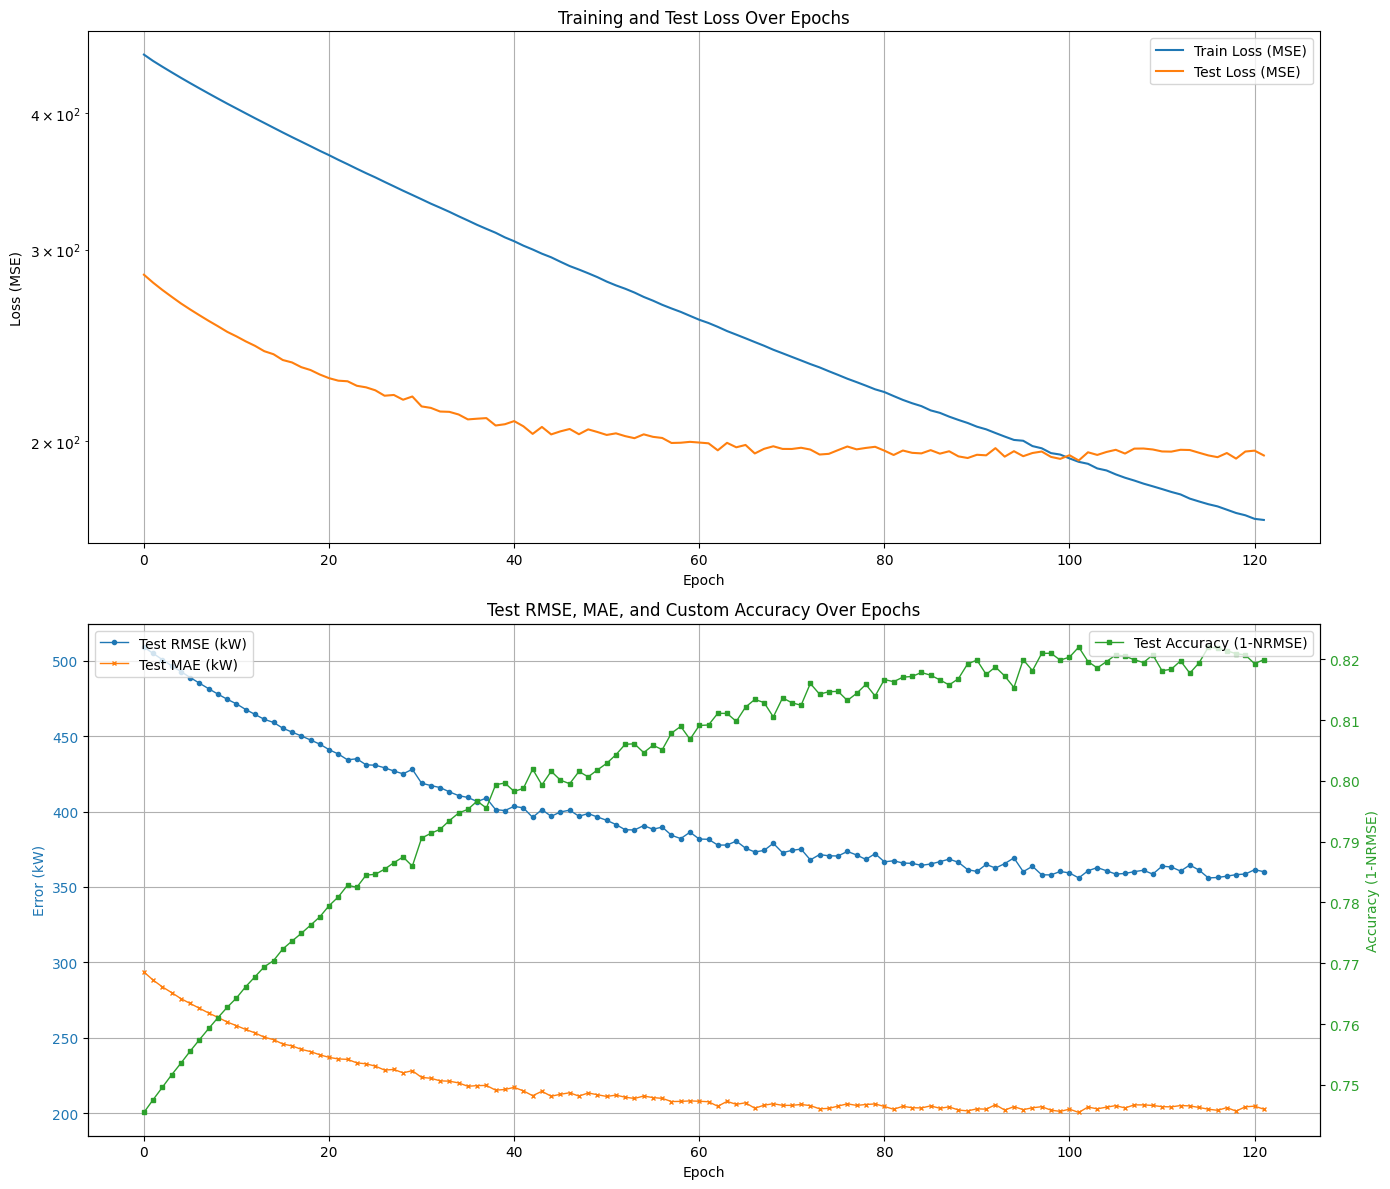

Plots generated successfully.


In [12]:
# Cell 7: Plotting Training Progress and Metrics

import matplotlib.pyplot as plt

print("\nGenerating plots for training progress and evaluation metrics...")

# Create a figure with two subplots
fig, axes = plt.subplots(2, 1, figsize=(14, 12)) # 2 rows, 1 column

# Plot 1: Training and Test Loss
axes[0].plot(train_losses, label='Train Loss (MSE)')
axes[0].plot(test_losses, label='Test Loss (MSE)')
axes[0].set_title('Training and Test Loss Over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True)
axes[0].set_yscale('log') # Use log scale for loss if values vary widely, optional. Remove if linear is clearer.


# Plot 2: Test RMSE, MAE, and Custom Accuracy
epochs_range = range(len(test_rmses)) # Assuming all metric lists have the same length

# Plot RMSE and MAE on the left y-axis
color1 = 'tab:blue'
color2 = 'tab:orange'
axes[1].plot(epochs_range, test_rmses, label='Test RMSE (kW)', color=color1, marker='o', markersize=3, linewidth=1)
axes[1].plot(epochs_range, test_maes, label='Test MAE (kW)', color=color2, marker='x', markersize=3, linewidth=1)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Error (kW)', color=color1)
axes[1].tick_params(axis='y', labelcolor=color1)
axes[1].set_title('Test RMSE, MAE, and Custom Accuracy Over Epochs')
axes[1].grid(True)
axes[1].legend(loc='upper left')

# Create a second y-axis for Custom Accuracy
ax2 = axes[1].twinx()
color3 = 'tab:green'
ax2.plot(epochs_range, test_custom_accs, label='Test Accuracy (1-NRMSE)', color=color3, marker='s', markersize=3, linewidth=1)
ax2.set_ylabel('Accuracy (1-NRMSE)', color=color3)
ax2.tick_params(axis='y', labelcolor=color3)
ax2.legend(loc='upper right')

plt.tight_layout() # Adjusts subplot parameters for a tight layout
plt.show()

print("Plots generated successfully.")

## inference


--- Performing Inference Demonstration ---
Loaded best model weights from best_model.pth

Making prediction for sample index 90 from the test set...
Input sequence shape for model: torch.Size([1, 96, 30])
True target sequence shape: torch.Size([16])

Predicted Power (kW) for next 240 minutes:
[123.009895 122.15991  121.543236 121.56328  120.57503  120.46693
 120.42287  119.55535  118.67294  118.48555  118.672165 117.33792
 117.52536  117.537285 116.95793  116.00634 ]
Actual Power (kW) for next 240 minutes:
[65.65714  54.714287 43.771427 32.82857  21.885714 10.942857  0.
  0.        0.        0.        0.        0.        0.        0.
 84.       44.3     ]


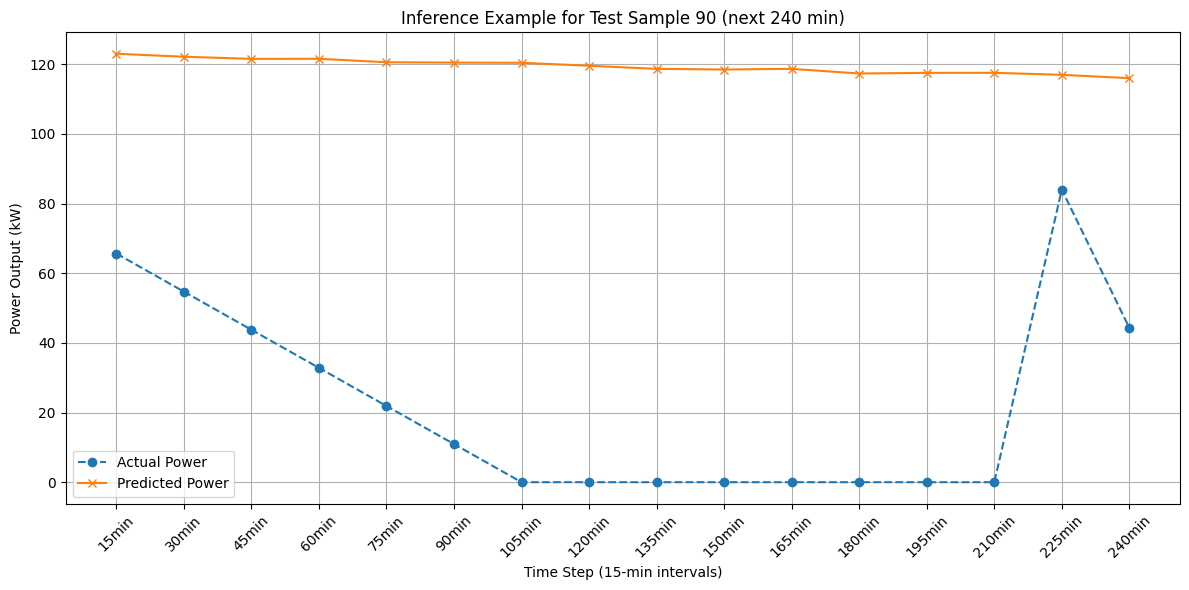


Inference demonstration complete.


In [14]:
# Cell X (New): Model Inference Demonstration

print("\n--- Performing Inference Demonstration ---")

# 1. Load the Best Trained Model
# Make sure this path matches the name of the best model saved from your training loop (Cell 6 or the LR tuning Cell).
# If you ran the LR tuning, it might be 'best_model_lr_X.X.pth'. Let's assume 'best_model.pth' for now.
# If you had a specific best LR from the tuning, change this:
# best_lr_found = # get this from your tuning results, e.g., sorted_results[0][0]
# model_path = f'best_model_lr_{best_lr_found}.pth'
model_path = 'best_model.pth' 

try:
    model.load_state_dict(torch.load(model_path))
    print(f"Loaded best model weights from {model_path}")
except FileNotFoundError:
    print(f"Error: Model file '{model_path}' not found. Please ensure training completed successfully.")
    # Exit or handle gracefully if model not found
    exit()

model.eval() # Set the model to evaluation mode for inference

# 2. Prepare "New" Input Data for Prediction
# We'll take a sample from the X_test_tensor. In a real application, this would be your
# most recent 'sequence_length' data points, preprocessed exactly like the training data.

sample_idx = 90 # Choose an index from your test set to visualize
# In a real scenario, you'd construct `new_input_data` from your latest sensor readings:
# new_input_data = [most_recent_seq_len_rows_of_features_and_target_for_inference]
# new_input_tensor = torch.tensor(new_input_data, dtype=torch.float32).unsqueeze(0).to(device)

input_sequence = X_test_tensor[sample_idx] # Shape: [sequence_length, num_features]
true_target_sequence = y_test_tensor[sample_idx] # Shape: [forecast_horizon_steps]

# Add a batch dimension (required by the model)
input_tensor_for_inference = input_sequence.unsqueeze(0).to(device) # Shape: [1, sequence_length, num_features]

print(f"\nMaking prediction for sample index {sample_idx} from the test set...")
print(f"Input sequence shape for model: {input_tensor_for_inference.shape}")
print(f"True target sequence shape: {true_target_sequence.shape}")


# 3. Make Prediction
with torch.no_grad(): # Disable gradient calculations for inference
    predicted_output_tensor = model(input_tensor_for_inference)

# 4. Process the Prediction
predicted_power_inference = predicted_output_tensor.cpu().numpy().flatten() # Remove batch dim, flatten
true_power_inference = true_target_sequence.cpu().numpy().flatten()

# Ensure predictions are non-negative (as power cannot be negative)
predicted_power_inference = np.maximum(0, predicted_power_inference)


print(f"\nPredicted Power (kW) for next {forecast_horizon_steps*15} minutes:")
print(predicted_power_inference)
print(f"Actual Power (kW) for next {forecast_horizon_steps*15} minutes:")
print(true_power_inference)

# 5. Visualize the Inference Result
plt.figure(figsize=(12, 6))
plt.plot(np.arange(forecast_horizon_steps), true_power_inference, label='Actual Power', marker='o', linestyle='--')
plt.plot(np.arange(forecast_horizon_steps), predicted_power_inference, label='Predicted Power', marker='x')

plt.title(f'Inference Example for Test Sample {sample_idx} (next {forecast_horizon_steps*15} min)')
plt.xlabel(f'Time Step ({15}-min intervals)')
plt.ylabel('Power Output (kW)')
plt.xticks(np.arange(forecast_horizon_steps), [f'{(s+1)*15}min' for s in range(forecast_horizon_steps)], rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nInference demonstration complete.")